# Human lymph node

The saved MELON joint embedding is paired with the existing spatial partition. Follow the barcode alignment from embedding to tissue coordinates and final labels.

Read the stored outputs below in order. These cells load and plot archived results; they do not preprocess inputs, train models, cluster spots, or fit a new UMAP/t-SNE.

Data: `Published_Data_non_NASH/02_Human_lymph_node/`. The sharedoc download link will be added after the archive is uploaded.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
sys.path.insert(0, str(repo / "Reproduce"))
from _shared.paper_plots import *
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "02_Human_lymph_node"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."


## 1. Read the saved MELON embedding and labels

Align `03_embeddings/MELON.csv` with the MELON column in `04_clusters/final_clusters.csv` by barcode.

In [2]:
embedding = read_indexed(DATA / "03_embeddings/MELON.csv")
labels = read_indexed(DATA / "04_clusters/final_clusters.csv")
embedding = align_embedding(embedding, labels)
assert len(labels) == 3484
display(pd.DataFrame({"spots": [len(labels)], "embedding_dimensions": [embedding.shape[1]],
                       "MELON_domains": [labels.MELON.nunique()]}))

,spots,embedding_dimensions,MELON_domains
0,3484,128,10


## 2. Display the MELON spatial domains

Each dot is one saved spot, colored by its existing MELON domain label.

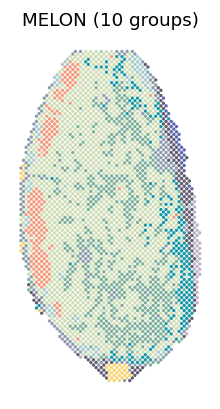

In [3]:
show(spatial_panels(labels, ["MELON"], ncols=1))

## 3. Read the stored t-SNE

The saved t-SNE has its own source embedding and domain column. Read both from `03_embeddings/supplementary_tsne/`; use these saved coordinates directly.

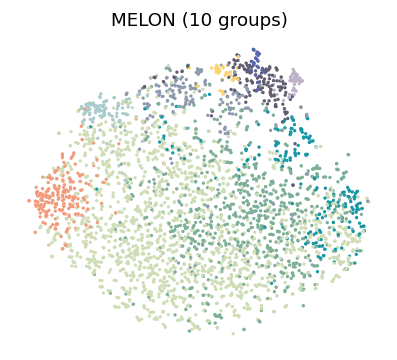

In [4]:
tsne = read_indexed(DATA / "03_embeddings/supplementary_tsne/saved_tsne.csv")
tsne_source = read_indexed(DATA / "03_embeddings/supplementary_tsne/source_embedding.csv")
tsne_source = align_embedding(tsne_source, tsne)
show(spatial_panels(tsne, ["melon_domain"], x="TSNE1", y="TSNE2", ncols=1, invert_y=False))